## Programa5.SeleccionAtributos

Noviembre 13, 2026

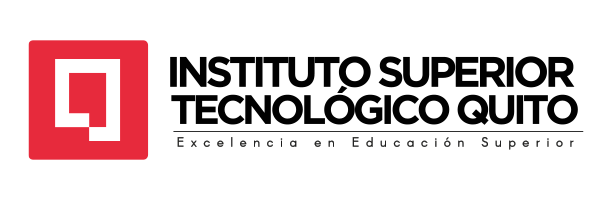

**Nombre:** Edgar Ulloa  
**Fecha:** *14-11-2026*    
**Link Repositorio:** https://github.com/eulloaitq/Fundamentos-de-Machine-Learning.git

# Descarga y registro de la fuente

In [17]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from ucimlrepo import fetch_ucirepo
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import StandardScaler

In [18]:
# Descargar el conjunto de datos desde UCI.
dataset = fetch_ucirepo(id=296)
 
# Obtener una copia de todos los datos.
df = dataset.data.original.copy()
 
# Verificar que cumple con el tamaño solicitado.
print("Instancias y atributos:", df.shape)
assert len(df) > 100_000, "El dataset debe superar los 100 000 registros."
 
# Visualizar los primeros registros.
display(df.head())
 
# Consultar el diccionario de atributos.
atributos = dataset.variables
display(atributos)
 
# Guardar una copia local para desarrollar la actividad.
df.to_csv("hospitalizaciones_diabetes_original.csv", index=False)

Instancias y atributos: (101766, 50)


C:\Users\edgar\anaconda3\envs\FundamentosMachineLearningITQ\Lib\site-packages\ucimlrepo\fetch.py:97: DtypeWarning: Columns (10: payer_code) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(data_url)


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


,name,role,type,demographic,description,units,missing_values
0,encounter_id,ID,,NaN,Unique identifier of an encounter,None,no
1,patient_nbr,ID,,NaN,Unique identifier of a patient,None,no
2,race,Feature,Categorical,Race,"Values: Caucasian, Asian, African American, Hi...",None,yes
3,gender,Feature,Categorical,Gender,"Values: male, female, and unknown/invalid",None,no
4,age,Feature,Categorical,Age,"Grouped in 10-year intervals: [0, 10), [10, 20...",None,no
5,weight,Feature,Categorical,NaN,Weight in pounds.,None,yes
6,admission_type_id,Feature,Categorical,NaN,Integer identifier corresponding to 9 distinct...,None,no
7,discharge_disposition_id,Feature,Categorical,NaN,Integer identifier corresponding to 29 distinc...,None,no
8,admission_source_id,Feature,Categorical,NaN,Integer identifier corresponding to 21 distinc...,None,no
9,time_in_hospital,Feature,Integer,NaN,Integer number of days between admission and d...,None,no


# Fase 1: Comprensión del negocio

## Planteamiento del problema

El problema que justifica este trabajo se presenta en el proceso de readmisiones hospitalarias, ya que estas ocurren cuando un paciente vuelve a ser hospitalizado después de haber recibido el alta médica. Este proyecto se enfoca en los pacientes con diabetes por cuanto resulta que las readmisiones de estos pacientes representan un aspecto importante para el análisis de la utilización de los servicios hospitalarios, en este sentido el problema que se desea estudiar consiste en comprender cómo se distribuyen las características de las hospitalizaciones y cómo se relacionan las readmisiones con estas.

Para realizar el análisis se ha seleccionado el dataset *Diabetes 130-US Hospitals for Years 1999–2008*, que contiene 101.766 registros de hospitalizaciones, al cual se le van a aplicar proceosos de exploración de los datos de modo que se pueda identificar los valores faltantes, si contiene registros repetidos, determinar los valores atípicos si hubieren y las diferencias que existan en las escalas de los atributos numéricos, todo esto con la finalidad de porder aplicar los algoritmos de Machine Learning.

## Actores interesados

Los principales actores interesados en este análisis son:

- **Administradores hospitalarios:** Necesitan conocer las características de las hospitalizaciones para gestionar la planificación de los servicios.
- **Personal médico:** Requieren los resultados para comprender mejor las características de los pacientes hospitalizados.
- **Analistas de datos:** Necesitan verificar la calidad de la información para preparar los atributos para los presentes y futuros análisis.
- **Investigadores académicos:** Pueden estudiar los patrones de hospitalización y readmisión utilizando técnicas estadísticas.

## Objetivo general

Analizar las características de las hospitalizaciones de pacientes con diabetes mediante las fases de comprensión del negocio, comprensión de los datos y preparación de datos de CRISP-DM, aplicando técnicas de normalización Min-Max y estandarización Z-score a los atributos cuantitativos.

## Preguntas de análisis

1. ¿Cómo se distribuyen la duración de las hospitalizaciones, los procedimientos médicos y la cantidad de medicamentos administrados contratados con las readmisiones?

2. ¿Cuál es la frecuencia con la que se presentan las diferentes categorías de readmisión hospitalaria?

3. ¿Qué valores faltantes, duplicados y valores atípicos se pueden encontrar en los atributos seleccionados?

4. ¿Qué diferencias se observan al aplicar la normalización y estandarización sobre los atributos?

## Criterios de éxito

Para establecer los criterios de éxito se debe considerar los siguientes aspectos:

- Se debe verificar la carga correcta de los 101.766 registros originales.
- Se debe identificar y documentar desde el dataset los tipos de atributos, los valores faltantes, los valores duplicados y los valores atípicos.
- Se debe analizar la distribución de las categorías de readmisión.
- Se debe seleccionar y preparar correctamente las atributos cuantitativos.
- Se debe comprobar que los atributos normalizados queden dentro del intervalo entre 0 y 1.
- Se debe generar los archivos CSV solicitados.

## Identificación del atributo readmitted

El atributo readmitted es undicador que registra una readmisión hospitalaria y el intervalo de tiempo transcurrido hasta que se realiza, Este atributo tiene tres categorias a saber:

| Categoría | Significado |
|:---:|---|
| NO | No se registra una readmisión del paciente. |
| <30 | El paciente fue readmitido en menos de 30 días. |
| >30 | El paciente fue readmitido después de 30 días. |

Se debe considerar que este atributo es categórico por lo tanto no se aplicará el proceso de normalización ni de estandarización sobre la misma, porque sus valores representan categorías y no mediciones numéricas continuas, por lo tanto se la utilizará como referencia para el análisis.

## Alcance y limitaciones del análisis

El dataset seleccionado contiene información acerca de las hospitalizaciones que han tenido pacientes con padecimiento de diabetes y que han sido registradas en 130 hospitales y redes de atención de Estados Unidos durante el periodo 1999–2008. Para realizar el análisis de esta información nos encontramos con las siguientes limitaciones:

- **Periodo de estudio:** Resulta necesario considerar que los registros médicos corresponden a una información histórica, por lo que sus resultados no necesariamente tienen relación con las condiciones actuales de los servicios hospitalarios.

- **Población analizada:** La información que contiene el dataset procede de hospitales y redes de atención en los Estados Unidos, por esta razon no se puede generalizar los resultados hacia otros países o sistemas de salud.

- **Hospitalizaciones repetidas:** Se debe tener presente que cada instancia del dataset representa una hospitalización y no necesariamente un paciente diferente, ya que un mismo paciente puede aparecer varias veces porque pudo haber sido hospitalizado en mas de una ocasion, por lo tanto se debe controlar que dichas repeticiones no se eliminen automáticamente.

- **Confidencialidad:** La información obtenida será utilizada unicamente con fines académicos, ya que no se identificará a los pacientes ni tampoco se relacionará sus registros con la información personal de los pacientes.

- **Limitaciones metodológicas:** El análisis de la información será descriptivo, no serviara para realizar diagnósticos médicos, ni establecer relaciones causales y no se entrenarán modelos predictivos en este ejercicio.

## Fase 2 Comprensión de los datos

## Exploración inicial del conjunto de datos

### Dimensiones del dataset

Se genera un reporte de las dimensiones reales y se verifica la carga de las 101 766 filas, haciendo una distinción del número de hospitalizaciones y el número de pacientes únicos.

In [19]:
# Dimensiones del dataset
print("Dimensiones (filas, columnas):", df.shape)

# Verificación de carga
print("Total de hospitalizaciones:", len(df))
assert len(df) == 101766, "No se cargaron las 101766 filas"

# Pacientes únicos
print("Total de pacientes únicos:", df["patient_nbr"].nunique())

# Pacientes con más de una hospitalización
print("Pacientes con múltiples hospitalizaciones:", (df["patient_nbr"].value_counts() > 1).sum())

Dimensiones (filas, columnas): (101766, 50)
Total de hospitalizaciones: 101766
Total de pacientes únicos: 71518
Pacientes con múltiples hospitalizaciones: 16773


### Diccionario de datos

Se genera un diccionario de datos para lograr un entendimiento racional de la información contenida en el dataset y poder determinarlos procesos a realizar. 

In [20]:
# Diccionario de datos de todos los atributos
cuantitativos = [
    "time_in_hospital", "num_lab_procedures", "num_procedures",
    "num_medications", "number_outpatient",
    "number_emergency", "number_inpatient"
]

identificadores = ["encounter_id", "patient_nbr"]

categoricos_numericas = [
    "admission_type_id", "discharge_disposition_id",
    "admission_source_id"
]

uci = dataset.variables.set_index("name")

diccionario = pd.DataFrame({
    "Nombre": df.columns,
    "Significado": [
        uci.loc[c, "description"] if c in uci.index else "No documentado"
        for c in df.columns
    ],
    "Tipo observado": df.dtypes.astype(str).values,
    "Tipo conceptual": [
        "Identificador" if c in identificadores else
        "Cuantitativa discreta" if c in cuantitativos else
        "Categórica ordinal" if c == "age" else
        "Categórica nominal"
        for c in df.columns
    ],
    "Unidades o categorías": [
        "Código identificador" if c in identificadores else
        "Días" if c == "time_in_hospital" else
        "Conteo" if c in cuantitativos else
        "NO, <30, >30" if c == "readmitted" else
        "Intervalos de edad" if c == "age" else
        "Códigos categóricos" if c in categoricos_numericas else
        "Categorías"
        for c in df.columns
    ],
    "Rol analítico": [
        "Identificación" if c in identificadores else
        "Escalamiento" if c in cuantitativos else
        "Referencia" if c == "readmitted" else
        "Descriptiva"
        for c in df.columns
    ]
})

print("Total de atributos documentados:", len(diccionario))
display(diccionario)

Total de atributos documentados: 50


,Nombre,Significado,Tipo observado,Tipo conceptual,Unidades o categorías,Rol analítico
0,encounter_id,Unique identifier of an encounter,int64,Identificador,Código identificador,Identificación
1,patient_nbr,Unique identifier of a patient,int64,Identificador,Código identificador,Identificación
2,race,"Values: Caucasian, Asian, African American, Hi...",str,Categórica nominal,Categorías,Descriptiva
3,gender,"Values: male, female, and unknown/invalid",str,Categórica nominal,Categorías,Descriptiva
4,age,"Grouped in 10-year intervals: [0, 10), [10, 20...",str,Categórica ordinal,Intervalos de edad,Descriptiva
5,weight,Weight in pounds.,str,Categórica nominal,Categorías,Descriptiva
6,admission_type_id,Integer identifier corresponding to 9 distinct...,int64,Categórica nominal,Códigos categóricos,Descriptiva
7,discharge_disposition_id,Integer identifier corresponding to 29 distinc...,int64,Categórica nominal,Códigos categóricos,Descriptiva
8,admission_source_id,Integer identifier corresponding to 21 distinc...,int64,Categórica nominal,Códigos categóricos,Descriptiva
9,time_in_hospital,Integer number of days between admission and d...,int64,Cuantitativa discreta,Días,Escalamiento


### Datos faltantes

Se realiza una análisis de los valores faltantes en la matriz.

In [5]:
# Valores nulos y ausentes (?)
nulos = df.isna()
interrogaciones = df.astype("string").apply(lambda atributo: atributo.str.strip().eq("?").fillna(False))
faltantes = nulos | interrogaciones

# Tabla resumen faltantes
resumen_faltantes = pd.DataFrame({
    "Atributo": df.columns,
    "Nulos": nulos.sum().values,
    "Marcadores (?)": interrogaciones.sum().values,
    "Total faltantes": faltantes.sum().values,
    "Porcentaje (%)": (faltantes.mean() * 100).round(2).values
})
resumen_faltantes = resumen_faltantes.sort_values("Total faltantes", ascending=False)

print("ANÁLISIS DE VALORES FALTANTES")
print("Total de registros:", len(df))
display(resumen_faltantes)
print("\nATRIBUTOS QUE CONTIENEN LA CATEGORÍA 'None':")

for atributo in df.columns:
    cantidad = df[atributo].astype("string").str.strip().eq("None").sum()
    if cantidad > 0:
        print(f"{atributo}: {cantidad} registros")

ANÁLISIS DE VALORES FALTANTES
Total de registros: 101766


,Atributo,Nulos,Marcadores (?),Total faltantes,Porcentaje (%)
5,weight,98569,0,98569,96.86
22,max_glu_serum,96420,0,96420,94.75
23,A1Cresult,84748,0,84748,83.28
11,medical_specialty,49949,0,49949,49.08
10,payer_code,40256,0,40256,39.56
2,race,2273,0,2273,2.23
20,diag_3,1423,0,1423,1.4
19,diag_2,358,0,358,0.35
18,diag_1,21,0,21,0.02
1,patient_nbr,0,0,0,0.0



ATRIBUTOS QUE CONTIENEN LA CATEGORÍA 'None':


### Resultado del análisis

Del análisis de los 50 atributos del dataset se ha identificado que 9 presentan valores faltantes y 41 no, los atributos con mayor porcentaje de datos faltantes son weight (96.86%), max_glu_serum (94.75%) y A1Cresult (83.28%), también se identificaron valores faltantes en medical_specialty (49.08%) y payer_code (39.56 %), mientras que los atributos relacionados con los diagnósticos presentan porcentajes considerablemente menores.

No se encontraron marcadores "?" en los datos cargados, posiblemente porque fueron interpretados como valores nulos durante la importación, además los atributos cuantitativos seleccionados para la normalización y estandarización no presentan valores faltantes.

### Revisión de duplicados

In [21]:
# Instancias duplicadas
instancias_duplicadas = df.duplicated().sum()

# Encuentros duplicados
encuentros_duplicados = df["encounter_id"].duplicated().sum()

# Resumenes
pacientes_unicos = df["patient_nbr"].nunique()
pacientes_multiples = (df["patient_nbr"].value_counts() > 1).sum()
hospitalizaciones_adicionales = (len(df) - pacientes_unicos)

print("REVISIÓN DE REGISTROS DUPLICADOS")
print("-" * 50)
print("Total de registros:", len(df))
print("Instancias completamente duplicadas:", instancias_duplicadas)
print("encounter_id duplicados:", encuentros_duplicados)
print("Pacientes únicos:", pacientes_unicos)
print("Pacientes con múltiples hospitalizaciones:", pacientes_multiples)
print("Hospitalizaciones adicionales:", hospitalizaciones_adicionales)

REVISIÓN DE REGISTROS DUPLICADOS
--------------------------------------------------
Total de registros: 101766
Instancias completamente duplicadas: 0
encounter_id duplicados: 0
Pacientes únicos: 71518
Pacientes con múltiples hospitalizaciones: 16773
Hospitalizaciones adicionales: 30248


### Resultado de la revisión

En la revisión de los registros duplicados del dataset considerando tanto las instancias completas como los identificadores encounter_id y patient_nbr, se encontró que un mismo paciente puede tener varias hospitalizaciones durante el periodo analizado, por lo tanto, la repetición de patient_nbr no representa necesariamente un error en los datos. 

El atributo encounter_id permite identificar cada hospitalización, mientras que patient_nbr identifica al paciente.

### Cálculos estadísticos

In [22]:
atributos = [
    "time_in_hospital",
    "num_lab_procedures",
    "num_procedures"
]

# Estadísticas descriptivas
display(df[atributos].describe().T)
print("")
# Frecuencias de readmisión
display(df["readmitted"].value_counts())
print("")
# Porcentajes de readmisión
display(df["readmitted"].value_counts(normalize=True) * 100)

,count,mean,std,min,25%,50%,75%,max
time_in_hospital,101766.0,4.395987,2.985108,1.0,2.0,4.0,6.0,14.0
num_lab_procedures,101766.0,43.095641,19.674362,1.0,31.0,44.0,57.0,132.0
num_procedures,101766.0,1.339730,1.705807,0.0,0.0,1.0,2.0,6.0


readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64

readmitted
NO     53.911916
>30    34.928169
<30    11.159916
Name: proportion, dtype: float64

### Resultados de las estadísticas descriptivas

Como resultado del análisis de las estadísticas descriptivas aplicadas a los atributos cuantitativos del dataset se han obtenido estos resultados:

- La duración promedio de las hospitalizaciones fue de 4.40 días, con una mediana de 4 días, tambien se registró un promedio de 43.10 procedimientos de laboratorio, 1.34 procedimientos adicionales y 16.02 medicamentos distintos administrados.  
- Respecto al atributo readmitted, se identificaron 54,864 hospitalizaciones sin readmisión que representan un 53.91%; 35,545 con readmisión después de 30 días es decir un 34.93% y 11,357 con readmisión antes de 30 días dando un 11.16%. 
- De acuerdo a los resultados obtenidos se observan diferencias importantes en las escalas y distribuciones de los atributos cuantitativos, por lo tanto se justifica la aplicación de técnicas de normalización y estandarización.

### Gráficos estadísticos

#### 1. Histograma: Días de hospitalización

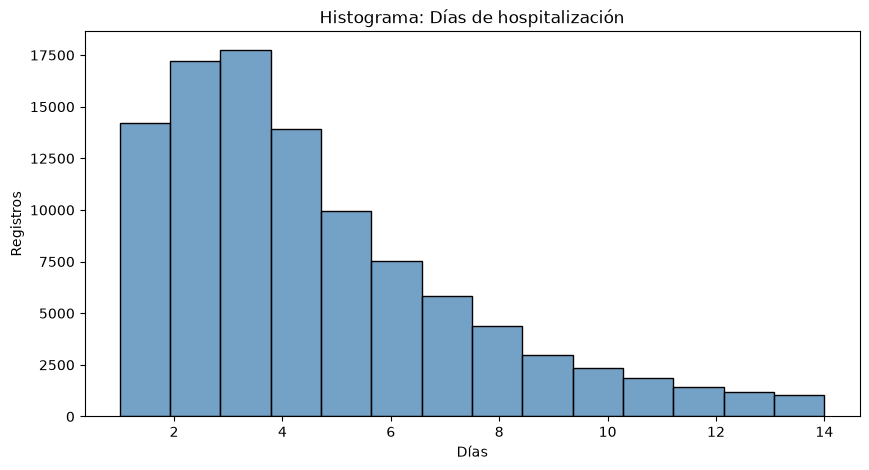

In [23]:
plt.figure(figsize=(10, 5))
sns.histplot(data=df, x="time_in_hospital", bins=14, color="steelblue")
plt.title("Histograma: Días de hospitalización")
plt.xlabel("Días")
plt.ylabel("Registros")
plt.show()

Analizando el histograma se aprecia que la mayor cantidad de hospitalizaciones se concentra dentro de un rango de 2 a 4 días, es notorio que a medida que aumentan los días hospitalización se disminuye la cantidad de registros, también se observa una distribución sesgada a la derecha debido a que existen menos hospitalizaciones de larga duración, lo que indica que predominan las estancias hospitalarias cortas, aunque también existen pacientes que requieren permanecer hospitalizados durante más tiempo.

#### 2. Gráfico de cajas y bigotes: Días de hospitalización

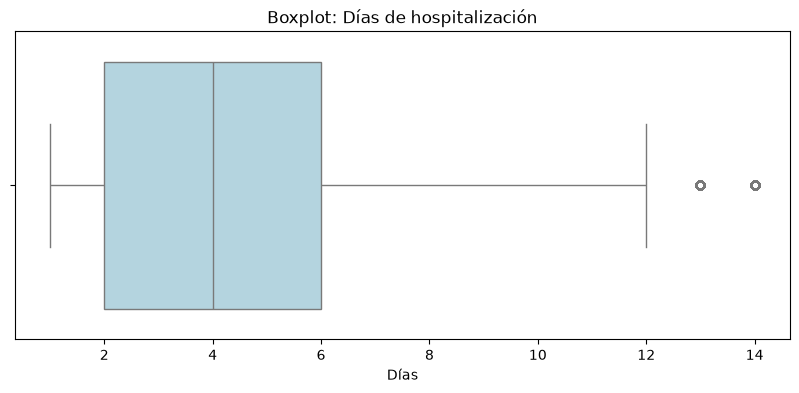

In [24]:
plt.figure(figsize=(10, 4))
sns.boxplot(data=df, x="time_in_hospital", color="lightblue")
plt.title("Boxplot: Días de hospitalización")
plt.xlabel("Días")
plt.show()

El diagrama de cajas y bigotes permite observar que la media de hospitalización es de 4 días, mientras que el primer cuartil (Q1) es de 2 días y el tercer cuartil (Q3) es de 6 días, lo que significa que el 50% de las hospitalizaciones cercanas a la tiene una duración de entre 2 a 6 días, además se pueden identificar algunos valores atípicos correspondientes a hospitalizaciones prolongadas que no necesariamente representan errores, puesto que deben existir pacienetes que requieren hospitalizaciones más largas debido a sus condiciones médicas por lo tanto, no deben eliminarse sin una justificación valida.

#### 3. Histograma: Número de medicamentos

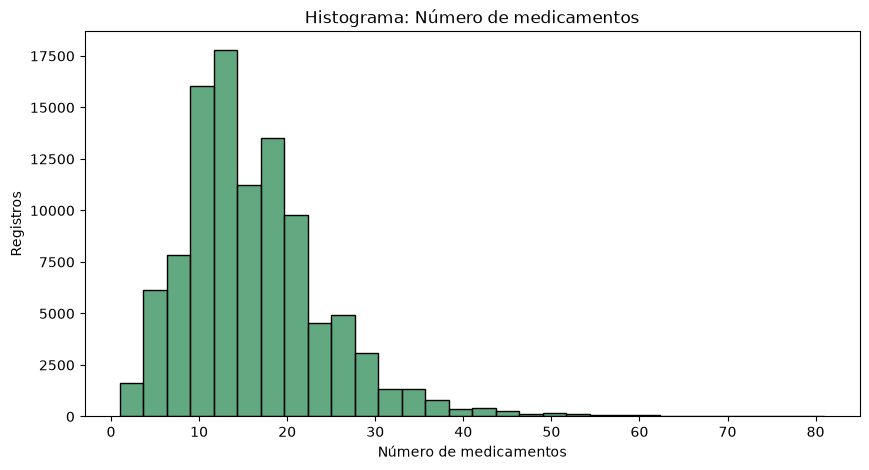

In [25]:
plt.figure(figsize=(10, 5))
sns.histplot(data=df, x="num_medications", bins=30, color="seagreen")
plt.title("Histograma: Número de medicamentos")
plt.xlabel("Número de medicamentos")
plt.ylabel("Registros")
plt.show()

En este histograma se aprecia la cantidad de medicamentos distintos administrados durante las hospitalizaciones, se puede observar que los valores van aproximadamente desde 1 hasta al mas de 80 medicamentos, la existencia de registros con cantidades elevadas de medicamentos indica que existe una variación en los tratamientos administrados durante las hospitalizaciones.

#### 4. Gráfico de cajas y bigotes: Número de medicamentos

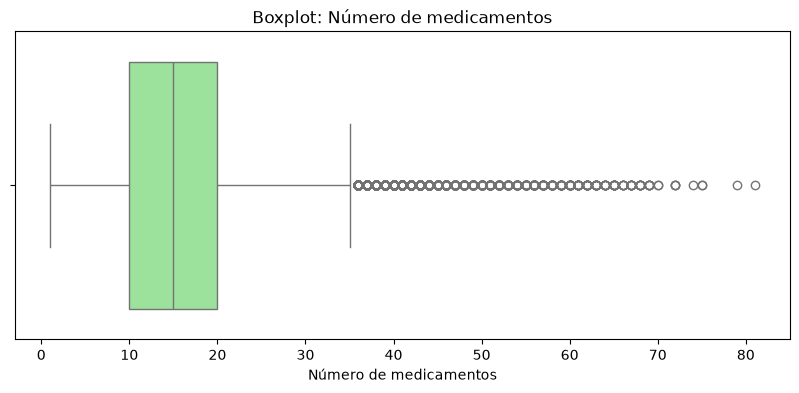

In [26]:
plt.figure(figsize=(10, 4))
sns.boxplot(data=df, x="num_medications", color="lightgreen")
plt.title("Boxplot: Número de medicamentos")
plt.xlabel("Número de medicamentos")
plt.show()

El gráfico de cajas y bigotes denota que la mediana es aproximadamente de 15 medicamentos, con un primer cuartil de 10 y un tercer cuartil de 20 medicamentos, esto significa que el 50% de las hospitalizaciones cercanas a la media registra entre 10 y 20 medicamentos distintos sin contar los outliers, ya que estos alcanzan un máximo que execede los 80 medicamentos, aunque esos valores elevados pueden identificarse como atípicos mediante el método del rango intercuartílico (IQR) no necesariamente representan errores, por lo que deben analizarse considerando el contexto hospitalario antes de decidir su tratamiento.

#### 5. Gráfico de barras: Frecuencias de readmisión

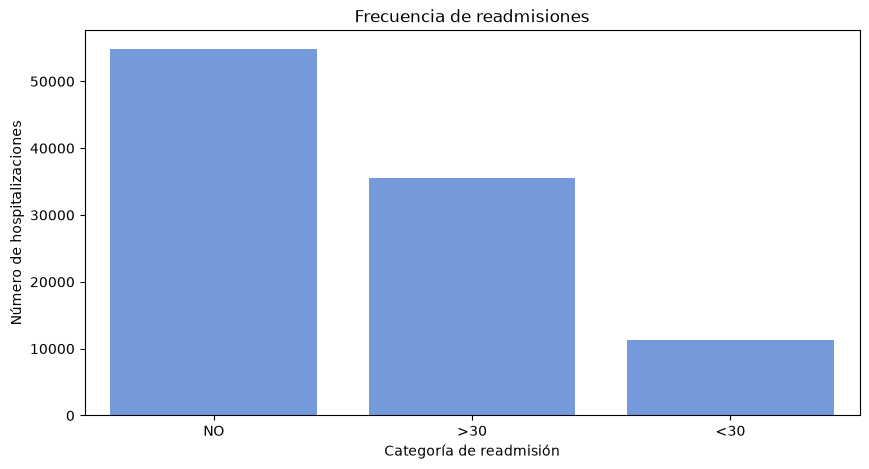

In [27]:
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x="readmitted", order=["NO", ">30", "<30"], color="cornflowerblue")
plt.title("Frecuencia de readmisiones")
plt.xlabel("Categoría de readmisión")
plt.ylabel("Número de hospitalizaciones")
plt.show()

El gráfico de barras muestra que según el atributo **readmitted** la categoría **NO** presenta la mayor frecuencia, le sigue la categoría **>30**, quedando de última la categoría **<30**. Estos resultados indican que la mayoría de las hospitalizaciones no presenta una readmisión registrada, que la mayoria de readminiones mayores a 30 días son más frecuentes y que las readmisiones que se suscitan antes de 30 días son mínimas lo cual podría relacionarse con pacientes críticos.

### Cálculo del rango intercuartílico (IQR)

Para el cálculo del rango intercuartílico vamos a utilizar los siguientes atributos:
- time_in_hospital: días de hospitalización.
- num_medications: número de medicamentos administrados.

In [28]:
atributos_iqr = ["time_in_hospital", "num_medications"]

for atributo in atributos_iqr:
    Q1 = df[atributo].quantile(0.25)
    Q3 = df[atributo].quantile(0.75)
    IQR = Q3 - Q1
    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR
    atipicos = (
        (df[atributo] < limite_inferior) |
        (df[atributo] > limite_superior)
    )
    cantidad = atipicos.sum()
    porcentaje = cantidad / len(df) * 100

    print("\nAtributo:", atributo)
    print("Q1:", Q1)
    print("Q3:", Q3)
    print("IQR:", IQR)
    print("Límite inferior:", limite_inferior)
    print("Límite superior:", limite_superior)
    print("Cantidad de valores atípicos:", cantidad)
    print(f"Porcentaje de valores atípicos: {porcentaje:.2f}%")


Atributo: time_in_hospital
Q1: 2.0
Q3: 6.0
IQR: 4.0
Límite inferior: -4.0
Límite superior: 12.0
Cantidad de valores atípicos: 2252
Porcentaje de valores atípicos: 2.21%

Atributo: num_medications
Q1: 10.0
Q3: 20.0
IQR: 10.0
Límite inferior: -5.0
Límite superior: 35.0
Cantidad de valores atípicos: 2557
Porcentaje de valores atípicos: 2.51%


### Interpretación de valores atípicos mediante IQR

#### 1. Atributo: time_in_hospital (Días de hospitalización)

En este atributo se obtuvo un primer cuartil (Q1) de 2 días y un tercer cuartil (Q3) de 6 días, con un rango intercuartílico (IQR) de 4 días, así mismo el límite inferior calculado fue de -4 días y el superior de 12 días, también se identificaron 2,252 valores atípicos, equivalentes al 2.21 % del total de hospitalizaciones.

**Decisión:** Se decide conservar las instancias que contienen los valores atípicos porque no existe evidencia suficiente para considerarlas como errores únicamente por su duración y pueden corresponder a hospitalizaciones prolongadas reales.

#### 2. Atributo: num_medications (Número de medicamentos)

En este otro atributo se obtuvo un primer cuartil (Q1) de 10 medicamentos y un tercer cuartil (Q3) de 20 medicamentos, con un rango intercuartílico (IQR) de 10, aqui el límite inferior fue de -5 y el superior de 35 medicamentos, también se identificaron 2,557 valores atípicos, equivalentes al 2.51 % del total de hospitalizaciones.

**Decisión:** Se decide igualmente conservar estos registros, ya que las cantidades elevadas de medicamentos podrían corresponder a tratamientos hospitalarios complejos, por lo que no se deben eliminar sin comprobar previamente si representan errores de registro.

## Fase 3 Selección y limpieza

#### 1. Selección de datos
El objetivo de la selección de los datos consiste en determinar cuáles son los atributos que serviran como base para realizar el análisis y cuáles se deben conservar como referencia, para esto se han establecido los siguientes criterios de selección:
- **Relevancia:** Consiste en seleccionar los atributos cuantitativos que tengan relevancia para el proceso, en este caso tenemos las relacionadas con hospitalización, procedimientos, medicamentos y visitas previas, porque son las que se utilizaran en la normalización y la estandarización.
- **Tipo de dato:** Consiste en seleccionar los atributos numéricos que puedan transformarse mediante la Normalización y la Estandarización.
- **Identificadores:** En este caso se van a conservar los atributos encounter_id y patient_nbr para mantener la trazabilidad, pero se los va a excluir del escalamiento porque sus valores no representan cantidades médicas.
- **Clase:** Para este caso se va establece el atributo readmitted como referencia para futuros análisis, sin escalarla porque es categórica.
- **Integridad:** Para esto se debe mantener el dataset original de 101,766 registros y 50 columnas sin modificarlo.

El resultado de la selección será una copia de trabajo con los siete atributos cuantitativos, los dos identificadores y el atributo readmitted.

#### 2. Limpieza de datos
El objetivo de la limpieza de datos consiste en verificar que las variables seleccionadas sean válidas y estén preparadas para las transformaciones, para este proceso se han establecido las siguientes reglas:
- **Valores faltantes:** Se debe comprobar si existen valores faltantes en los siete atributos numéricos, sin eliminar instancias cuando se encuentran valores faltantes en los atributos que no han sido considerados para el escalamiento.
- **Duplicados:** Es necesario verificar los valores duplicados completos y de encounter_id, y tampoco se pueden eliminar automáticamente las hospitalizaciones repetidas de un mismo paciente, por cuanto pueden corresponder a distintas instancias reales.
- **Inconsistencias:** Se debe comprobar que los datos sean numéricos, no negativos y que los días de hospitalización estén entre 1 y 14, según el rango documentado del dataset.
- **Valores atípicos:** Se debe conservar los valores identificados mediante IQR, porque pueden representar situaciones hospitalarias reales.
- **Tipos de datos:** Es necesario documentar las conversiones realizadas y conservar una copia de los datos numéricos limpios antes de aplicar cualquier transformación.

#### Selección de datos

In [29]:
atributos = [
    "time_in_hospital",
    "num_lab_procedures",
    "num_procedures",
    "num_medications",
    "number_outpatient",
    "number_emergency",
    "number_inpatient"
]

referencias = ["encounter_id", "patient_nbr", "readmitted"]

print("ANTES DE LA SELECCIÓN")
print("Instancias:", df.shape[0])
print("Atributos:", df.shape[1])

assert len(df) > 100000

# Seleccionar atributos y referencias
df_seleccionado = df[referencias + atributos].copy()

print("\nDESPUÉS DE LA SELECCIÓN")
print("Instancias:", df_seleccionado.shape[0])
print("Atributos:", df_seleccionado.shape[1])
print("Atributos para escalamiento:", len(atributos))
print("Atributos de referencia:", len(referencias))

ANTES DE LA SELECCIÓN
Instancias: 101766
Atributos: 50

DESPUÉS DE LA SELECCIÓN
Instancias: 101766
Atributos: 10
Atributos para escalamiento: 7
Atributos de referencia: 3


Para realizar la selección de datos se tomo el dataset original que contiene 101,766 hospitalizaciones y 50 atributos, de estos se seleccionaron siete atributos cuantitativos relevantes para el análisis relacionados con la duración de hospitalización, los procedimientos médicos, los medicamentos administrados y las visitas previas. 

Adicionalmente, se conservaron los identificadores encounter_id y patient_nbr, junto con el atributo categórico readmitted, para mantener la trazabilidad y permitir análisis posteriores, obteniendo como resultado la creación de un conjunto de trabajo con 10 atributos, de los cuales únicamente siete se utilizarán para la normalización y la estandarización.

#### Limpieza de datos

In [30]:
df_limpio = df_seleccionado.copy()

print("\nANTES DE LA LIMPIEZA")
print("Instancias:", df_limpio.shape[0])
print("Atributos:", df_limpio.shape[1])

# Revición de duplicados
print("\nDuplicados completos:", df_limpio.duplicated().sum())
print("Identificadores encounter_id duplicados:", df_limpio["encounter_id"].duplicated().sum())

# Validación de tipos numéricos
for atributo in atributos:
    tipo_anterior = df_limpio[atributo].dtype
    df_limpio[atributo] = pd.to_numeric(df_limpio[atributo], errors="coerce")
    print(f"{atributo}: {tipo_anterior} -> {df_limpio[atributo].dtype}")

# Revisión de faltantes e inconsistencias
print("\nValores faltantes numéricos:", df_limpio[atributos].isna().sum().sum())
print("Valores negativos:", (df_limpio[atributos] < 0).sum().sum())
print("Valores infinitos:", np.isinf(df_limpio[atributos].to_numpy(dtype=float)).sum())
print("Días fuera de 1 a 14:", (~df_limpio["time_in_hospital"].between(1, 14)).sum())

# Validación antes de continuar
assert df_limpio[atributos].notna().all().all()
assert (df_limpio[atributos] >= 0).all().all()
assert np.isfinite(df_limpio[atributos].to_numpy(dtype=float)).all()
assert df_limpio["time_in_hospital"].between(1, 14).all()

# Copia numérica antes de transformar
datos_numericos_limpios = df_limpio[atributos].copy()

print("\nDESPUÉS DE LA LIMPIEZA")
print("Instancias:", df_limpio.shape[0])
print("Atributos:", df_limpio.shape[1])
print("Instancias eliminadas:", len(df_seleccionado) - len(df_limpio))
print("Atributos eliminados durante la limpieza:", df_seleccionado.shape[1] - df_limpio.shape[1])


ANTES DE LA LIMPIEZA
Instancias: 101766
Atributos: 10

Duplicados completos: 0
Identificadores encounter_id duplicados: 0
time_in_hospital: int64 -> int64
num_lab_procedures: int64 -> int64
num_procedures: int64 -> int64
num_medications: int64 -> int64
number_outpatient: int64 -> int64
number_emergency: int64 -> int64
number_inpatient: int64 -> int64

Valores faltantes numéricos: 0
Valores negativos: 0
Valores infinitos: 0
Días fuera de 1 a 14: 0

DESPUÉS DE LA LIMPIEZA
Instancias: 101766
Atributos: 10
Instancias eliminadas: 0
Atributos eliminados durante la limpieza: 0


Para realizar la limpieza se establecieron una serie de reglas que sirvieros para verificar los valores faltantes, los duplicados, las inconsistencias y los tipos de datos, en función de los resultados se tomo la decisión de no eliminar automáticamente las hospitalizaciones repetidas de un mismo paciente, porque pueden representar eventos médicos diferentes, también se conservaron los valores atípicos identificados mediante IQR, considerando que pueden corresponder a situaciones hospitalarias reales.

Luego se verificó que los siete atributos seleccionados contengan valores numéricos válidos, sin valores faltantes, negativos o infinitos, y que los días de hospitalización se encuentren dentro del rango documentado, y finalmente, se conservó una copia de los siete atributos cuantitativos antes de aplicar cualquier transformación, manteniendo de esta manera intacto el dataset original.

## Selección de atributos cuantitativos

In [34]:
atributos = [
    "time_in_hospital",
    "num_lab_procedures",
    "num_procedures",
    "num_medications",
    "number_outpatient",
    "number_emergency",
    "number_inpatient"
]

# Selección de los siete atributos
df_cuantitativos = datos_numericos_limpios[atributos].copy()

print("ATRIBUTOS CUANTITATIVOS SELECCIONADOS")
print("-" * 50)
for atributo in df_cuantitativos.columns:
    print("Atributo:", atributo)
    print("Tipo de dato:", df_cuantitativos[atributo].dtype)
    print("Valores faltantes:", df_cuantitativos[atributo].isna().sum())
    print("-" * 50)

print("\nRESUMEN")
print("Instancia:", df_cuantitativos.shape[0])
print("Atributo:", df_cuantitativos.shape[1])
print("Todas son numéricas:", all(pd.api.types.is_numeric_dtype(df_cuantitativos[c]) for c in atributos))

ATRIBUTOS CUANTITATIVOS SELECCIONADOS
--------------------------------------------------
Atributo: time_in_hospital
Tipo de dato: int64
Valores faltantes: 0
--------------------------------------------------
Atributo: num_lab_procedures
Tipo de dato: int64
Valores faltantes: 0
--------------------------------------------------
Atributo: num_procedures
Tipo de dato: int64
Valores faltantes: 0
--------------------------------------------------
Atributo: num_medications
Tipo de dato: int64
Valores faltantes: 0
--------------------------------------------------
Atributo: number_outpatient
Tipo de dato: int64
Valores faltantes: 0
--------------------------------------------------
Atributo: number_emergency
Tipo de dato: int64
Valores faltantes: 0
--------------------------------------------------
Atributo: number_inpatient
Tipo de dato: int64
Valores faltantes: 0
--------------------------------------------------

RESUMEN
Instancia: 101766
Atributo: 7
Todas son numéricas: True


Del dataset "Diabetes 130-US Hospitals for Years 1999–2008" se seleccionaron siete atributos cuantitativos, considerando su significado y tipo de dato, ya que estos representan valores o cantidades relacionadas con la duración de hospitalización, los procedimientos médicos, los medicamentos administrados y las visitas hospitalarias previas, asimismo se excluyeron del escalamiento los identificadores encounter_id y patient_nbr, porque únicamente permiten identificar registros y pacientes, también se excluyeron los atributos admission_type_id, discharge_disposition_id y admission_source_id, debido a que sus valores numéricos representan categorías y no cantidades continuas. 

El atributo "age" no se incluyó porque está registrada mediante intervalos de edad y no como una medida numérica continua, de este modo la selección permite trabajar con siete atributos apropiados para aplicar el proceso de normalización y estandarización, sin alterar el significado de los atributos categóricos ni de los identificadores.

## Normalización Min Max

In [35]:
# Copia de los siete atributos limpios
df_minmax = datos_numericos_limpios.copy()

# Normalización Min-Max
scaler_minmax = MinMaxScaler(feature_range=(0, 1))
df_minmax = pd.DataFrame(
    scaler_minmax.fit_transform(df_minmax),
    columns=datos_numericos_limpios.columns,
    index=datos_numericos_limpios.index
)

# Mostrar las diez primeras instancias
print("PRIMERAS 10 INSTANCIAS NORMALIZADAS")
display(df_minmax.head(10))

# Comparar mínimos y máximos
comparacion = pd.DataFrame({
    "Mínimo antes": datos_numericos_limpios.min(),
    "Máximo antes": datos_numericos_limpios.max(),
    "Mínimo después": df_minmax.min(),
    "Máximo después": df_minmax.max()
})
print("\nCOMPARACIÓN ANTES Y DESPUÉS")
display(comparacion)

# Comprobar rango con tolerancia numérica
tolerancia = 1e-9
rango_valido = ((df_minmax >= -tolerancia) & (df_minmax <= 1 + tolerancia)).all().all()

# Validación de correspondencia de instancias y atributos
instancias_correctas = df_minmax.index.equals(datos_numericos_limpios.index)
atributos_correctos = df_minmax.columns.equals(datos_numericos_limpios.columns)
print("\nVALIDACIONES")
print("Valores dentro del rango [0, 1]:", rango_valido)
print("Correspondencia de instancias:", instancias_correctas)
print("Nombres de categorias conservadas:", atributos_correctos)
print("Instancias:", df_minmax.shape[0])
print("Categorías:", df_minmax.shape[1])

# Identificación de categorías constantes
constantes = datos_numericos_limpios.columns[datos_numericos_limpios.nunique() == 1].tolist()
print("\nCategorías constantes:", constantes)

assert rango_valido
assert instancias_correctas
assert atributos_correctos

PRIMERAS 10 INSTANCIAS NORMALIZADAS


,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient
0,0.000000,0.305344,0.000000,0.0000,0.000000,0.0,0.000000
1,0.153846,0.442748,0.000000,0.2125,0.000000,0.0,0.000000
2,0.076923,0.076336,0.833333,0.1500,0.047619,0.0,0.047619
3,0.076923,0.328244,0.166667,0.1875,0.000000,0.0,0.000000
4,0.000000,0.381679,0.000000,0.0875,0.000000,0.0,0.000000
5,0.153846,0.229008,1.000000,0.1875,0.000000,0.0,0.000000
6,0.230769,0.526718,0.166667,0.2500,0.000000,0.0,0.000000
7,0.307692,0.549618,0.000000,0.1375,0.000000,0.0,0.000000
8,0.923077,0.511450,0.333333,0.3375,0.000000,0.0,0.000000
9,0.846154,0.244275,0.500000,0.2125,0.000000,0.0,0.000000



COMPARACIÓN ANTES Y DESPUÉS


,Mínimo antes,Máximo antes,Mínimo después,Máximo después
time_in_hospital,1,14,0.0,1.0
num_lab_procedures,1,132,0.0,1.0
num_procedures,0,6,0.0,1.0
num_medications,1,81,0.0,1.0
number_outpatient,0,42,0.0,1.0
number_emergency,0,76,0.0,1.0
number_inpatient,0,21,0.0,1.0



VALIDACIONES
Valores dentro del rango [0, 1]: True
Correspondencia de instancias: True
Nombres de categorias conservadas: True
Instancias: 101766
Categorías: 7

Categorías constantes: []


Sobre una copia del dataset original se realizó la normalización de los siete atributos cuantitativos previamente seleccionados y limpiados aplicando la técnica de normalización Min-Max mediante MinMaxScaler de Scikit-learn con un rango de transformación de 0 a 1, conservando los nombres de los atributos y la correspondencia de los registros originales. Realizando la comparación de los valores mínimos y máximos antes y después de la transformación se puede verificar que los atributos normalizadas se encuentran dentro del intervalo establecido.

El proceso de normalización Min-Max facilita la comparación de los atributos que originalmente presentan escalas diferentes como los días de hospitalización, el número de procedimientos y los medicamentos administrados, pero resulta que esta técnica es sensible a los valores extremos, porque utiliza el mínimo y el máximo de cada atributo, por esta razón los registros con cantidades elevadas pueden comprimir los valores habituales hacia la parte inferior del intervalo.

En el caso de un atributo constante, MinMaxScaler evita la división por cero y asigna el valor 0 a todos sus registros cuando se utiliza el rango entre 0 y 1 y finalmente, se conserva el conjunto de datos normalizado en df_minmax sin modificar los atributos numéricos originales.

## Estandarización Z-score

In [36]:
# Copia de los siete atributos limpios
df_zscore = datos_numericos_limpios.copy()

# Estandarización Z-score
scaler_zscore = StandardScaler()
df_zscore = pd.DataFrame(
    scaler_zscore.fit_transform(df_zscore),
    columns=datos_numericos_limpios.columns,
    index=datos_numericos_limpios.index
)

# Mostrar las diez primeras instancias
print("PRIMERAS 10 INSTANCIAS ESTANDARIZADAS")
display(df_zscore.head(10))

# Cálculo de la media y la desviación estándar
print("\nVERIFICACIÓN DE MEDIA Y DESVIACIÓN ESTÁNDAR")

tolerancia = 1e-9
for atributo in df_zscore.columns:
    media = df_zscore[atributo].mean()
    desviacion = df_zscore[atributo].std(ddof=0)
    constante = datos_numericos_limpios[atributo].nunique() == 1
    media_correcta = np.isclose(media, 0, atol=tolerancia)
    desviacion_esperada = 0 if constante else 1
    desviacion_correcta = np.isclose(desviacion, desviacion_esperada, atol=tolerancia)
    print("\nAtributo:", atributo)
    print(f"Media: {media:.10f}")
    print(f"Desviación estándar: {desviacion:.10f}")
    print("Media aproximadamente 0:", media_correcta)
    print("Desviación correcta:", desviacion_correcta)

    assert media_correcta
    assert desviacion_correcta

# Verificar correspondencia de filas y columnas
assert df_zscore.index.equals(datos_numericos_limpios.index)
assert df_zscore.columns.equals(datos_numericos_limpios.columns)

print("\nRESULTADO FINAL")
print("Instancias:", df_zscore.shape[0])
print("Atributos:", df_zscore.shape[1])
print("Estandarización completada correctamente.")

PRIMERAS 10 INSTANCIAS ESTANDARIZADAS


,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient
0,-1.137649,-0.106517,-0.785398,-1.848268,-0.291461,-0.21262,-0.503276
1,-0.467653,0.808384,-0.785398,0.243390,-0.291461,-0.21262,-0.503276
2,-0.802651,-1.631351,2.145781,-0.371804,1.286748,-0.21262,0.288579
3,-0.802651,0.045967,-0.199162,-0.002688,-0.291461,-0.21262,-0.503276
4,-1.137649,0.401761,-0.785398,-0.986997,-0.291461,-0.21262,-0.503276
5,-0.467653,-0.614795,2.732016,-0.002688,-0.291461,-0.21262,-0.503276
6,-0.132655,1.367490,-0.199162,0.612506,-0.291461,-0.21262,-0.503276
7,0.202343,1.519973,-0.785398,-0.494842,-0.291461,-0.21262,-0.503276
8,2.882327,1.265834,0.387074,1.473776,-0.291461,-0.21262,-0.503276
9,2.547329,-0.513139,0.973309,0.243390,-0.291461,-0.21262,-0.503276



VERIFICACIÓN DE MEDIA Y DESVIACIÓN ESTÁNDAR

Atributo: time_in_hospital
Media: 0.0000000000
Desviación estándar: 1.0000000000
Media aproximadamente 0: True
Desviación correcta: True

Atributo: num_lab_procedures
Media: 0.0000000000
Desviación estándar: 1.0000000000
Media aproximadamente 0: True
Desviación correcta: True

Atributo: num_procedures
Media: -0.0000000000
Desviación estándar: 1.0000000000
Media aproximadamente 0: True
Desviación correcta: True

Atributo: num_medications
Media: -0.0000000000
Desviación estándar: 1.0000000000
Media aproximadamente 0: True
Desviación correcta: True

Atributo: number_outpatient
Media: 0.0000000000
Desviación estándar: 1.0000000000
Media aproximadamente 0: True
Desviación correcta: True

Atributo: number_emergency
Media: 0.0000000000
Desviación estándar: 1.0000000000
Media aproximadamente 0: True
Desviación correcta: True

Atributo: number_inpatient
Media: -0.0000000000
Desviación estándar: 1.0000000000
Media aproximadamente 0: True
Desviación c

La estandaritzación de los atributos se la realizó sobre una copia independiente de los datos, sin utilizar los resultados de la normalización Min-Max asegurando de este modo que ambas técnicas parten de la misma información original y pueden compararse posteriormente, para esto se conservaron los nombres de los atributos y la correspondencia de las instancias.

El proceso de estandarización transforma los valores de cada atributo no constante para obtener una media aproximadamente igual a 0 y una desviación estándar aproximadamente igual a 1, a diferencia del proceso Min-Max, los resultados aqui pueden contener valores negativos y valores superiores a 1, entonces los valores negativos representan observaciones inferiores a la media, mientras que los positivos representan observaciones superiores a la misma. Para poder verificar los resultados se calcularon las medias y desviaciones estándar utilizando ddof=0, de acuerdo con el procedimiento empleado por StandardScaler, y se aplicaron tolerancias numéricas, es así que en caso de existir atributos constantes se considera que sus valores estandarizados serán 0, con media y desviación estándar iguales a 0, y finalmente, los datos estandarizados se conservaron en df_zscore, manteniendo intactos los datos numéricos originales.

## Comparación y exportación de datos

In [37]:
# Definición de las tres versiones de los datos
versiones = {
    "Original": datos_numericos_limpios,
    "Min-Max": df_minmax,
    "Z-score": df_zscore
}

# Comparación de las tres versiones
estadisticas = []
for nombre, datos in versiones.items():
    for atributo in datos.columns:
        estadisticas.append({
            "Atributo": atributo,
            "Versión": nombre,
            "Mínimo": datos[atributo].min(),
            "Máximo": datos[atributo].max(),
            "Media": datos[atributo].mean(),
            "Desviación": datos[atributo].std(ddof=0)
        })

comparacion = pd.DataFrame(estadisticas)
display(comparacion.round(4))

,Atributo,Versión,Mínimo,Máximo,Media,Desviación
0,time_in_hospital,Original,1.0000,14.0000,4.3960,2.9851
1,num_lab_procedures,Original,1.0000,132.0000,43.0956,19.6743
2,num_procedures,Original,0.0000,6.0000,1.3397,1.7058
3,num_medications,Original,1.0000,81.0000,16.0218,8.1275
4,number_outpatient,Original,0.0000,42.0000,0.3694,1.2673
5,number_emergency,Original,0.0000,76.0000,0.1978,0.9305
6,number_inpatient,Original,0.0000,21.0000,0.6356,1.2629
7,time_in_hospital,Min-Max,0.0000,1.0000,0.2612,0.2296
8,num_lab_procedures,Min-Max,0.0000,1.0000,0.3213,0.1502
9,num_procedures,Min-Max,0.0000,1.0000,0.2233,0.2843


Se compararon los siete atributos cuantitativos en sus versiones original, normalizada mediante Min-Max y estandarizada mediante Z-score, determinando que los atributos originales presentan diferentes escalas y unidades de medida, por ejemplo: Los días de hospitalización varían entre 1 y 14, los procedimientos de laboratorio varían entre 1 y 132 y los medicamentos administrados varían entre 1 y 81; por lo tanto estas diferencias justifican la aplicación de técnicas de transformación que permitan comparar atributos con magnitudes distintas.

Los resultados de la normalización Min-Max muestran que los siete atributos fueron transformadas correctamente al intervalo de 0 a 1, sin embargo, algunos atributos presentan medias normalizadas muy cercanas a cero, como number_outpatient (0.0088) y number_emergency (0.0026), esto ocurre porque existen valores máximos elevados en comparación con la mayoría de las observaciones lo que provoca que los valores habituales se concentren cerca del límite inferior.

Como resultado de la estandarización Z-score, los siete atributos presentan medias aproximadamente iguales a 0 y desviaciones estándar iguales a 1, lo que confirma que la estandarización se realizó correctamente, también se observan valores negativos y positivos, así como máximos superiores a 1, esto es normal porque Z-score representa la distancia de cada observación respecto de la media medida en desviaciones estándar, un dato que llama la atención es que el atributo number_emergency cuyo valor máximo estandarizado alcanza 81.4667 evidencia la presencia de registros extremadamente alejados del promedio.

En conclusión ambas técnicas permiten transformar los atributos con escalas diferentes, pero producen resultados distintos, la normalización Min-Max establece un intervalo común de 0 a 1, mientras que la estandarización Z-score centra los datos alrededor de cero y establece una desviación estándar de 1. Las dos transformaciones conservan la forma general de las distribuciones y no eliminan los valores atípicos, por lo tanto, la elección de una técnica dependerá de las características de los datos y de los requisitos del algoritmo de Machine Learning que se utilice posteriormente.

### Gráficos comparativos de las tres versiones

#### Gráfico 1. Días de hospitalización

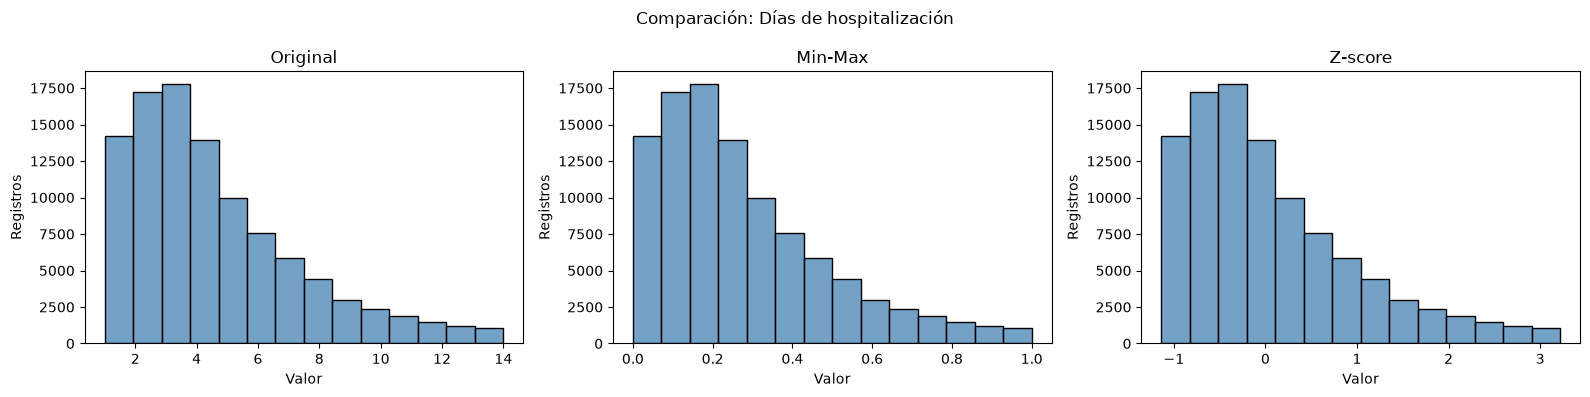

In [38]:
atributo = "time_in_hospital"
fig, ejes = plt.subplots(1, 3, figsize=(16, 4))
for eje, (nombre, datos) in zip(ejes, versiones.items()):
    sns.histplot(data=datos, x=atributo, bins=14, color="steelblue", ax=eje)
    eje.set_title(nombre)
    eje.set_xlabel("Valor")
    eje.set_ylabel("Registros")
fig.suptitle("Comparación: Días de hospitalización")
plt.tight_layout()
plt.show()

#### Gráfico 2. Número de medicamentos

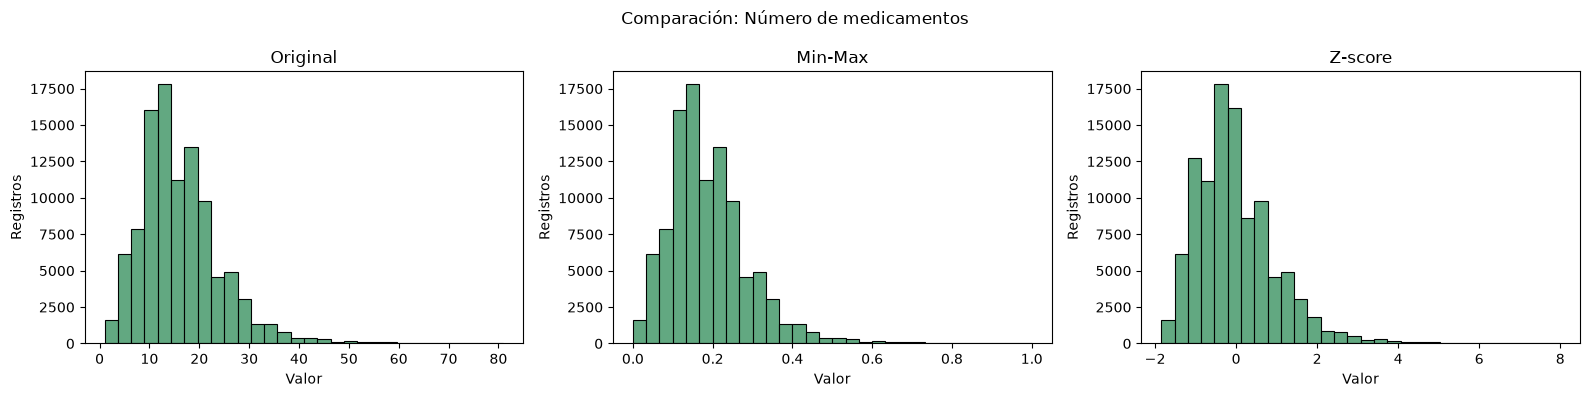

In [39]:
atributo = "num_medications"
fig, ejes = plt.subplots(1, 3, figsize=(16, 4))
for eje, (nombre, datos) in zip(ejes, versiones.items()):
    sns.histplot(data=datos, x=atributo, bins=30, color="seagreen", ax=eje)
    eje.set_title(nombre)
    eje.set_xlabel("Valor")
    eje.set_ylabel("Registros")
fig.suptitle("Comparación: Número de medicamentos")
plt.tight_layout()
plt.show()

Se ha realizado una comparación de las distribuciones de los atributos time_in_hospital y num_medications en sus versiones original, normalizada y estandarizada, utilizando histogramas de frecuencias para cada version, los valores de los datos originales se presentan en sus unidades correspondientes.

Con la normalización Min_Max, los valores han sido transformados a magnitudes que se escalan en un intervalo entre 0 y 1 modificando la escala horizontal pero manteniendo la distribución de las instancias, en cambio con la estandarización Z-score, los valores se expresan en desviaciones estándar respecto de la media, por lo que pueden aparecer valores negativos y positivos, sin que ello represente errores, ambos procesos conservan la forma general de la distribución, incluyendo su asimetría y la posición relativa de los valores extremos, por lo tanto, la normalización y la estandarización modifican la escala de los datos, pero no eliminan los valores atípicos ni cambian el orden de las observaciones.

### Demostración manual con cinco valores

In [40]:
# Atributo para la demostración
atributo = "time_in_hospital"

# Parámetros originales
minimo = datos_numericos_limpios[atributo].min()
maximo = datos_numericos_limpios[atributo].max()
media = datos_numericos_limpios[atributo].mean()
desviacion = datos_numericos_limpios[atributo].std(ddof=0)

print("PARÁMETROS UTILIZADOS")
print("Mínimo:", minimo)
print("Máximo:", maximo)
print("Media:", media)
print("Desviación estándar:", desviacion)
print("\nCÁLCULOS MANUALES Y COMPARACIÓN")

# Se obtienen cinco registros, conservando su índice original
for indice, valor in datos_numericos_limpios[atributo].iloc[:5].items():
    minmax_manual = (valor - minimo) / (maximo - minimo)
    zscore_manual = (valor - media) / desviacion
    minmax_python = df_minmax.loc[indice, atributo]
    zscore_python = df_zscore.loc[indice, atributo]
    
    print("\nRegistro:", indice)
    print("Valor original:", valor)
    print(f"Min-Max manual: ({valor} - {minimo}) / " f"({maximo} - {minimo}) = {minmax_manual:.6f}")
    print(f"Min-Max Python: {minmax_python:.6f}")
    print(f"Z-score manual: ({valor} - {media:.6f}) / " f"{desviacion:.6f} = {zscore_manual:.6f}")
    print(f"Z-score Python: {zscore_python:.6f}")

    assert np.isclose(minmax_manual, minmax_python, atol=1e-9)
    assert np.isclose(zscore_manual, zscore_python, atol=1e-9)

print("\nLos cálculos manuales coinciden con Python.")

PARÁMETROS UTILIZADOS
Mínimo: 1
Máximo: 14
Media: 4.395986871843248
Desviación estándar: 2.985093100907283

CÁLCULOS MANUALES Y COMPARACIÓN

Registro: 0
Valor original: 1
Min-Max manual: (1 - 1) / (14 - 1) = 0.000000
Min-Max Python: 0.000000
Z-score manual: (1 - 4.395987) / 2.985093 = -1.137649
Z-score Python: -1.137649

Registro: 1
Valor original: 3
Min-Max manual: (3 - 1) / (14 - 1) = 0.153846
Min-Max Python: 0.153846
Z-score manual: (3 - 4.395987) / 2.985093 = -0.467653
Z-score Python: -0.467653

Registro: 2
Valor original: 2
Min-Max manual: (2 - 1) / (14 - 1) = 0.076923
Min-Max Python: 0.076923
Z-score manual: (2 - 4.395987) / 2.985093 = -0.802651
Z-score Python: -0.802651

Registro: 3
Valor original: 2
Min-Max manual: (2 - 1) / (14 - 1) = 0.076923
Min-Max Python: 0.076923
Z-score manual: (2 - 4.395987) / 2.985093 = -0.802651
Z-score Python: -0.802651

Registro: 4
Valor original: 1
Min-Max manual: (1 - 1) / (14 - 1) = 0.000000
Min-Max Python: 0.000000
Z-score manual: (1 - 4.395987)

Se seleccionaron cinco instancias del atributo time_in_hospital para realizar una comprobacion manual de los procesos de normalización Min-Max y de estandarización Z-score, para Min-Max se utilizaron los valores mínimo y máximo originales y para Z-score se emplearon la media y la desviación estándar poblacional (ddof=0).

Los resultados manuales se compararon con los obtenidos mediante MinMaxScaler y StandardScaler, utilizando una tolerancia numérica de $10^{-9}$, esta comprobación ha permitido verificar que las transformaciones aplicadas por Python se corresponden con las fórmulas matemáticas estudiadas y que las instancias mantienen su correspondencia con los datos originales.

### Exportación a CSV

In [41]:
# Verificación de correspondencia entre las tres versiones
assert datos_numericos_limpios.index.equals(df_minmax.index)
assert datos_numericos_limpios.index.equals(df_zscore.index)
assert datos_numericos_limpios.columns.equals(df_minmax.columns)
assert datos_numericos_limpios.columns.equals(df_zscore.columns)

# Exporta a csv conservando el índice de referencia
df_minmax.to_csv(
    "datos_normalizados.csv",
    index=True,
    index_label="indice_original"
)

df_zscore.to_csv(
    "datos_estandarizados.csv",
    index=True,
    index_label="indice_original"
)

# Comprobación de los archivos exportados
normalizados_csv = pd.read_csv("datos_normalizados.csv", index_col="indice_original")
estandarizados_csv = pd.read_csv("datos_estandarizados.csv", index_col="indice_original")

assert normalizados_csv.index.equals(df_minmax.index)
assert estandarizados_csv.index.equals(df_zscore.index)
assert normalizados_csv.columns.equals(df_minmax.columns)
assert estandarizados_csv.columns.equals(df_zscore.columns)
assert np.allclose(normalizados_csv, df_minmax, atol=1e-9)
assert np.allclose(estandarizados_csv, df_zscore, atol=1e-9)

print("ARCHIVOS EXPORTADOS CORRECTAMENTE")
print("1. datos_normalizados.csv")
print("2. datos_estandarizados.csv")
print("\nInstancias normalizadas:", len(normalizados_csv))
print("Instancias estandarizadas:", len(estandarizados_csv))
print("Atributos en cada archivo:", len(df_minmax.columns))
print("Índices y valores verificados correctamente.")

ARCHIVOS EXPORTADOS CORRECTAMENTE
1. datos_normalizados.csv
2. datos_estandarizados.csv

Instancias normalizadas: 101766
Instancias estandarizadas: 101766
Atributos en cada archivo: 7
Índices y valores verificados correctamente.


Se exportaron los siete atributos cuantitativos normalizados y estandarizados a los archivos denominados **datos_normalizados.csv** y **datos_estandarizados.csv**, ambos archivos conservan los nombres y el orden de los atributos así como un índice de referencia denominado **indice_original**, el mismo que permite relacionar los registros transformados con el conjunto de datos utilizado en la preparación, tambien se comprobó que los archivos exportados mantienen la correspondencia de los registros y que sus valores coinciden con los resultados calculados en Python, dentro de una tolerancia numérica.

Los identificadores de pacientes y hospitalizaciones no fueron incluidos entre los atributos escalados, respetando su función como referencias y no como medidas cuantitativas, de este modo se obtuvieron dos conjuntos de datos independientes y preparados para análisis posteriores de Machine Learning sin la necesidad de modificar el dataset original.